## Load any data set and find out the covariance between two fields and also find the correlation and determine how two fields are correlated. Also handle the outliers in the data.

### Step-01 importing Dependencies

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

### Step-02. Data Generation/Creation

In [2]:
data = {
    'YearsExperience': [
        1, 2, 3, 4, 5, 6, 7, 8, 9, 10,
        2, 3, 4, 5, 6, 7, 8, 9, 10, 15
    ],
    'Salary': [
        25000, 30000, 35000, 40000, 45000,
        50000, 55000, 60000, 65000, 70000,
        28000, 33000, 38000, 43000, 48000,
        53000, 58000, 63000, 68000, 200000
    ]
}

In [4]:
df = pd.DataFrame(data)

In [22]:
df

,YearsExperience,Salary
0,1,25000
1,2,30000
2,3,35000
3,4,40000
4,5,45000
5,6,50000
6,7,55000
7,8,60000
8,9,65000
9,10,70000


In [6]:
df.head()

,YearsExperience,Salary
0,1,25000
1,2,30000
2,3,35000
3,4,40000
4,5,45000


In [8]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 2 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   YearsExperience  20 non-null     int64
 1   Salary           20 non-null     int64
dtypes: int64(2)
memory usage: 452.0 bytes
None


### Step-03 Visualization 

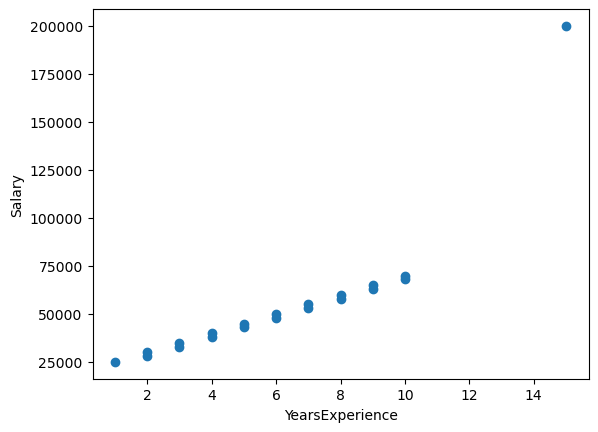

In [10]:
plt.scatter(df['YearsExperience'], df['Salary'])
plt.xlabel('YearsExperience')
plt.ylabel('Salary')
plt.show()

#### 01. Find covariance between experience and salary

In [12]:
covariance = df['YearsExperience'].cov(df['Salary'])

In [15]:
print('Covariance:',covariance)

Covariance: 108084.21052631579


#### 02. Find Correlation

In [16]:
correlation = df['YearsExperience'].corr(df['Salary'])

In [17]:
print('Correlation:', correlation)

Correlation: 0.8554779580520816


#### 03. Visualization using Scattered Plot

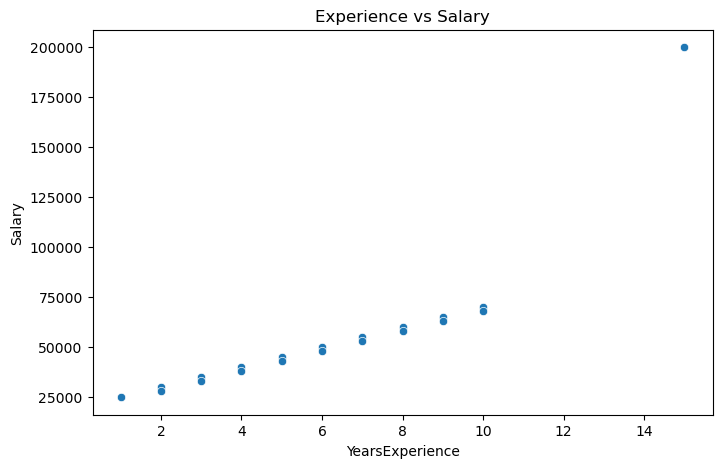

In [20]:
plt.figure(figsize=(8,5))
sns.scatterplot(
    data = df,
    x = 'YearsExperience',
    y = 'Salary'
)
plt.title('Experience vs Salary')
plt.show()


### Step-04 Detecting Outliers

In [23]:
Q1 = df['Salary'].quantile(.25)
Q3 = df['Salary'].quantile(.75)

In [24]:
IQR = Q3 -Q1

In [25]:
lower = Q1 -1.5 * IQR
upper = Q3 + 1.5 * IQR 

In [28]:
print('Q1: ',Q1)
print('Q3: ',Q3)
print('IQR: ',IQR)
print('lower limit: ',lower)
print('upper limit: ',upper)


Q1:  37250.0
Q3:  60750.0
IQR:  23500.0
lower limit:  2000.0
upper limit:  96000.0


In [29]:
# Outlier

outliers = df[
    (df['Salary'] > upper) |
    (df['Salary'] < lower)
]

In [31]:
print('Outlier: ',outliers)

Outlier:      YearsExperience  Salary
19               15  200000


### Step-05 Visualization Using Boxplot

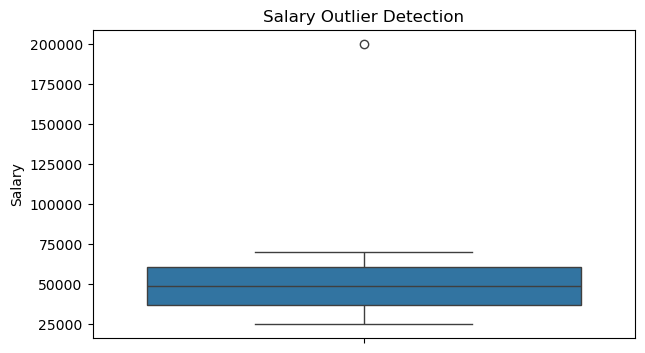

In [32]:
plt.figure(figsize=(7,4))
sns.boxplot(y = df['Salary'])
plt.title('Salary Outlier Detection')
plt.show()

#### 01. IQR capping to remove outliers

In [33]:
df_clean = df.copy()
df_clean['Salary'] = df_clean['Salary'].clip(
    lower =  lower,
    upper = upper
)

In [34]:
df_clean

,YearsExperience,Salary
0,1,25000
1,2,30000
2,3,35000
3,4,40000
4,5,45000
5,6,50000
6,7,55000
7,8,60000
8,9,65000
9,10,70000


#### 02. calculate covariance before and after handling outliers

In [35]:
cov_before = df['YearsExperience'].cov(df['Salary'])
cov_after = df['YearsExperience'].cov(df_clean['Salary'])

In [38]:
print('Covariance Before Handling',cov_before)
print('Covariance After Handling',cov_after)

Covariance Before Handling 108084.21052631579
Covariance After Handling 59915.789473684206


#### 03. calculate correlation before and after handling outliers

In [39]:
corr_before = df['YearsExperience'].corr(df['Salary'])
corr_after = df['YearsExperience'].corr(df_clean['Salary'])

In [40]:
print('Correlation Before: ', corr_before)
print('Correlation After: ', corr_after)

Correlation Before:  0.8554779580520816
Correlation After:  0.9981054467558145
